# Eleição Presidencial 2026 — Análise neutra dos Boletins de Urna

**Objetivo:** descrever os resultados e procurar anomalias estatísticas **sem hipótese prévia sobre quem ganha ou perde com elas**.
Cada teste é aplicado de forma simétrica a todos os candidatos e, sempre que possível, comparado com o que se esperaria
apenas por acaso (modelo nulo). Um "outlier" sozinho não é indício de fraude: em ~470 mil seções, eventos de 1 em 100 mil
acontecem algumas vezes por puro acaso.

**Fonte:** Boletins de Urna (BU) publicados pelo TSE em <https://dadosabertos.tse.jus.br> — um registro por seção eleitoral,
com votos por candidato, eleitores aptos, comparecimento, horários e identificação da urna.

Para atualizar os dados: `uv run baixar && uv run processar` e reexecute o notebook.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.ensemble import IsolationForest

from eleicoes_2026 import analise as A

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (11, 5), "figure.dpi": 110, "axes.titleweight": "bold"})
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.max_columns = 40

T = {t: A.carregar_secoes(t) for t in (1, 2)}
TURNOS = [t for t, df in T.items() if df is not None]
for t in (1, 2):
    df = T[t]
    print(f"{t}º turno:", "não disponível ainda (rode `uv run baixar --turno 2 && uv run processar --turno 2`)" if df is None
          else f"{len(df):,} seções | {df['votos_total'].sum():,} votos | {df['uf'].nunique()} UFs")

1º turno: 499,206 seções | 125,275,835 votos | 28 UFs
2º turno: 499,205 seções | 128,236,074 votos | 28 UFs


## 1. Qualidade e consistência dos dados
Testes aritméticos que todo BU deveria satisfazer. Violações aqui indicariam erro de registro ou de publicação, não necessariamente de votação.

In [2]:
for t in TURNOS:
    print(f"\n{t}º turno")
    display(A.checar_consistencia(T[t]))
    display(T[t]["ds_tipo_urna"].value_counts().rename("seções por tipo de urna").to_frame())


1º turno


,secoes_violando,pct
comparecimento + abstenções = aptos,0,0.000
votos (cand+branco+nulo) = comparecimento,0,0.000
comparecimento <= aptos,0,0.000
seção sem aptos,0,0.000
seção duplicada,0,0.000
BU emitido antes do encerramento,0,0.000
encerramento antes da abertura,0,0.000


,seções por tipo de urna
ds_tipo_urna,
Apurada,499206



2º turno


,secoes_violando,pct
comparecimento + abstenções = aptos,0,0.000
votos (cand+branco+nulo) = comparecimento,0,0.000
comparecimento <= aptos,0,0.000
seção sem aptos,0,0.000
seção duplicada,0,0.000
BU emitido antes do encerramento,0,0.000
encerramento antes da abertura,0,0.000


,seções por tipo de urna
ds_tipo_urna,
Apurada,499205


## 2. Resultado
### 2.1 Nacional

,votos,% válidos
FLAVIO BOLSONARO,"56,104,503",47.025705
LULA,"53,879,538",45.160782
ESCRITOR AUGUSTO CURY,"3,448,569",2.890524
RENAN SANTOS,"2,675,887",2.242877
RONALDO CAIADO,"2,605,148",2.183584
ZEMA,"326,488",0.273656
SAMARA,"122,911",0.103022
HERTZ DIAS,"43,103",0.036128
CLARIANA BARAO,"40,043",0.033563
EDMILSON COSTA,"22,693",0.019021


,votos,% válidos
LULA,"64,256,232",51.785183
FLAVIO BOLSONARO,"59,826,041",48.214817


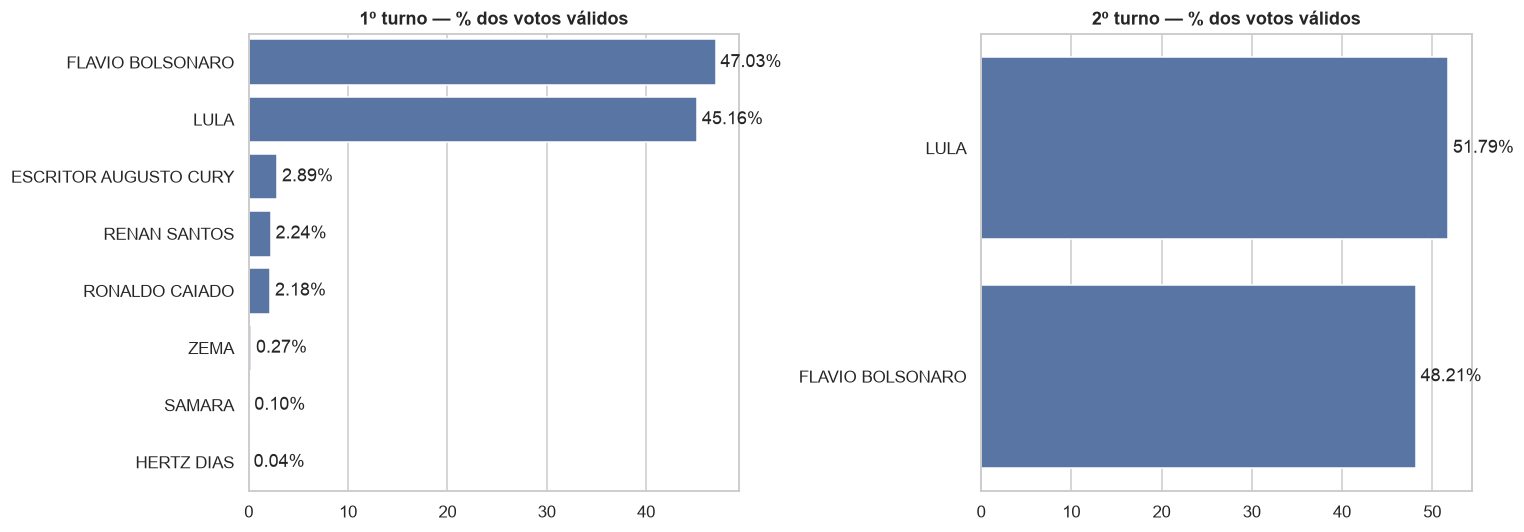

In [3]:
fig, axes = plt.subplots(1, len(TURNOS), figsize=(7 * len(TURNOS), 5), squeeze=False)
for ax, t in zip(axes[0], TURNOS):
    r = A.resultado(T[t])
    display(r.assign(votos=r["votos"].map("{:,}".format)).rename(columns={"pct_validos": "% válidos"}).head(12).style.set_caption(f"{t}º turno"))
    top = r.head(8)
    sns.barplot(x=top["pct_validos"], y=top.index, ax=ax, color="#4C72B0")
    ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
    ax.set(title=f"{t}º turno — % dos votos válidos", xlabel="", ylabel="")
plt.tight_layout()

### 2.2 Por UF e região

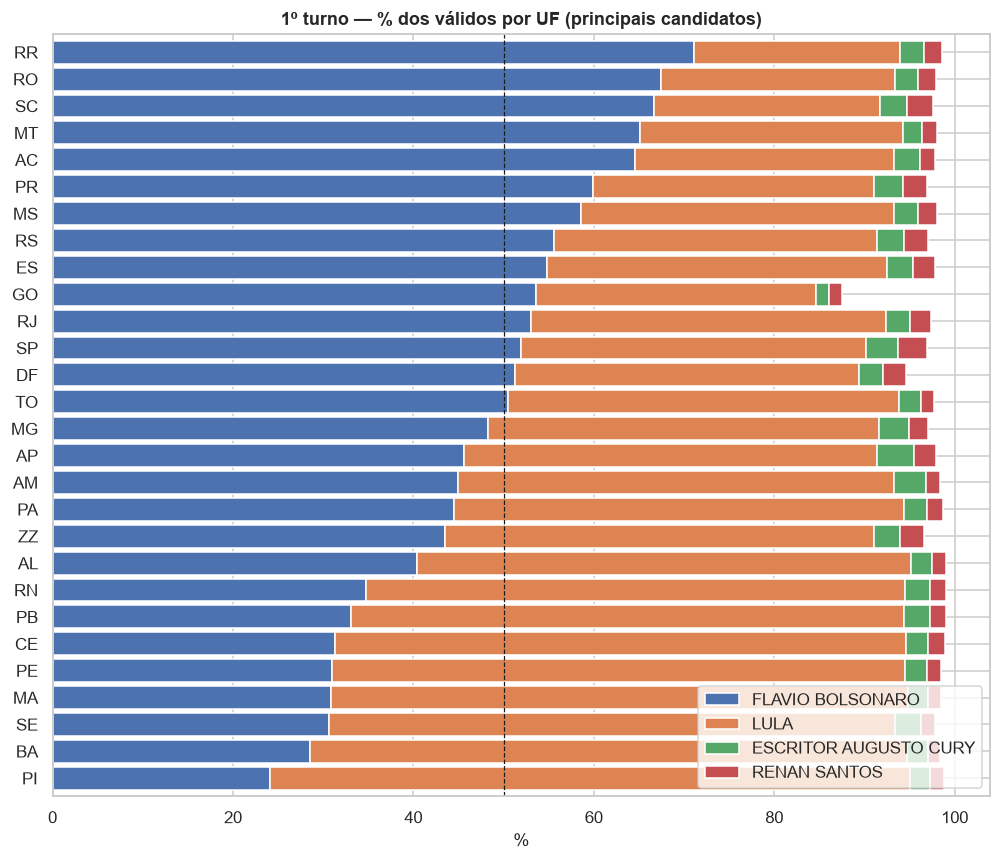

,FLAVIO BOLSONARO,LULA,ESCRITOR AUGUSTO CURY,RENAN SANTOS
regiao,,,,
Centro-Oeste,56.510,32.620,1.970,1.830
Exterior,43.470,47.550,2.940,2.590
Nordeste,30.850,63.770,2.430,1.570
Norte,49.150,44.650,2.860,1.740
Sudeste,51.360,39.680,3.330,2.720
Sul,60.080,31.280,3.050,2.730


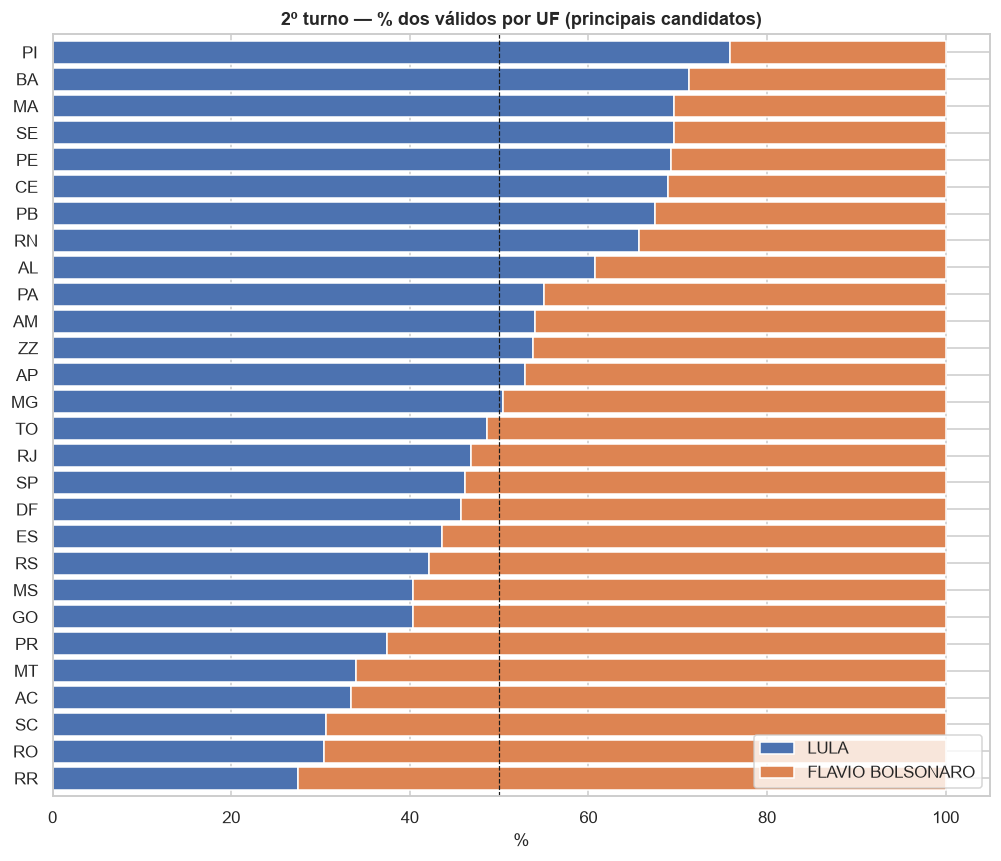

,LULA,FLAVIO BOLSONARO
regiao,,
Centro-Oeste,39.990,60.010
Exterior,53.860,46.140
Nordeste,69.370,30.630
Norte,50.010,49.990
Sudeste,47.240,52.760
Sul,37.420,62.580


In [4]:
for t in TURNOS:
    df = T[t]
    cands = A.principais(df, 4 if t == 1 else 2)
    por_uf = A.resultado(df, "uf")[cands].sort_values(cands[0])
    ax = por_uf.plot.barh(stacked=True, figsize=(11, 9), width=0.85)
    ax.set(title=f"{t}º turno — % dos válidos por UF (principais candidatos)", xlabel="%", ylabel="")
    ax.axvline(50, color="k", lw=0.8, ls="--")
    ax.legend(loc="lower right")
    plt.show()
    display(A.resultado(df, "regiao")[cands].round(2))

## 3. Distribuições por seção
Histogramas da % de comparecimento e da % de cada candidato por seção. Distribuições suaves e unimodais (ou bimodais
explicadas por geografia, como Norte/Nordeste vs Sul) são o esperado. Picos isolados em valores extremos (por exemplo
100% de comparecimento) merecem inspeção.

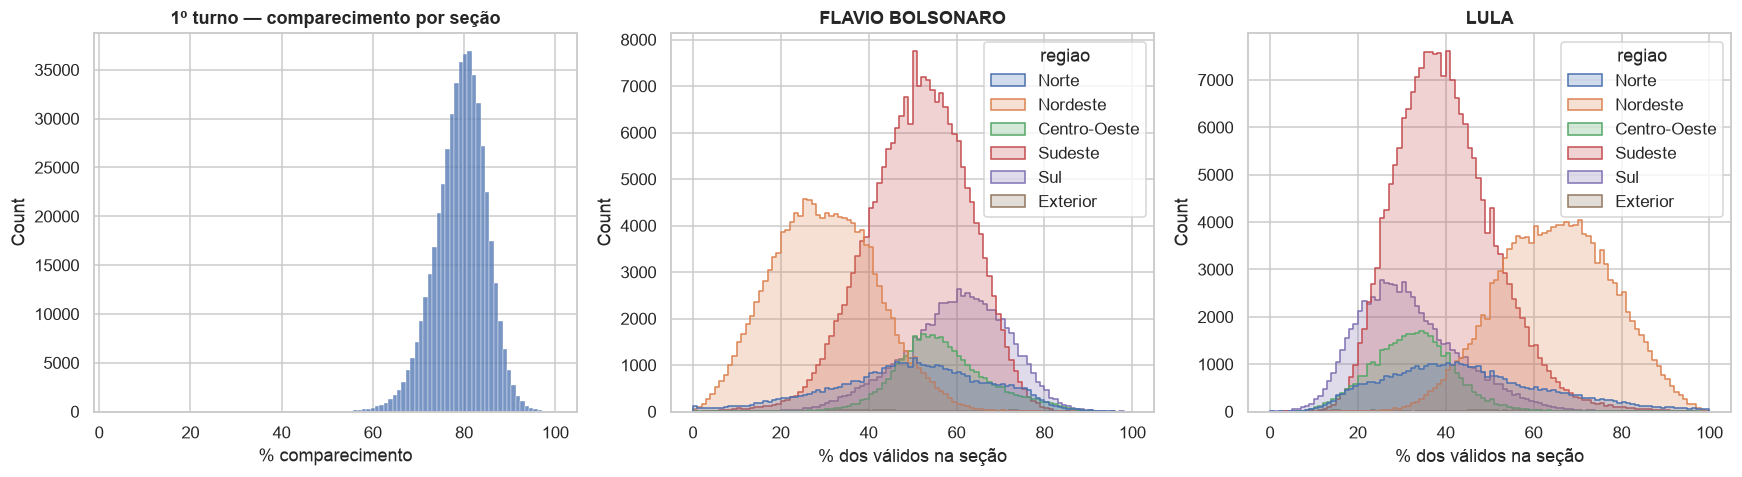

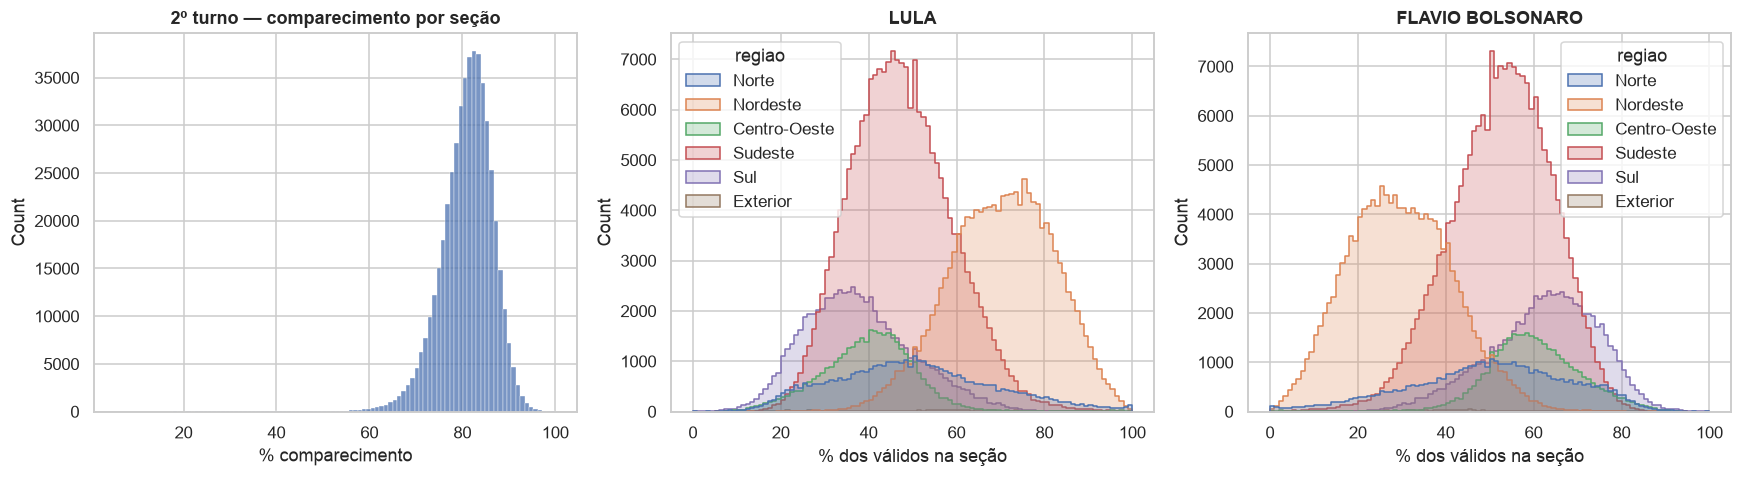

In [5]:
for t in TURNOS:
    df = T[t]
    cands = A.principais(df, 2)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    sns.histplot(df["comparecimento_pct"].clip(0, 1) * 100, bins=100, ax=axes[0])
    axes[0].set(title=f"{t}º turno — comparecimento por seção", xlabel="% comparecimento")
    for ax, c in zip(axes[1:], cands):
        share = df[c] / df["votos_validos"].replace(0, np.nan) * 100
        sns.histplot(x=share, hue=df["regiao"], bins=100, ax=ax, element="step", stat="count", common_norm=False)
        ax.set(title=f"{c}", xlabel="% dos válidos na seção")
    plt.tight_layout(); plt.show()

## 4. "Impressão digital" eleitoral (Klimek et al., 2012)
Histograma 2D de **comparecimento × % do candidato** por seção. Em eleições com enchimento de urnas aparece uma
"mancha" anômala no canto superior direito (≈100% de comparecimento e ≈100% de votos para um candidato), ligada ao
resto da nuvem por uma "ponte". Eleições limpas mostram uma nuvem compacta. Mostramos os dois principais candidatos
para manter a simetria.

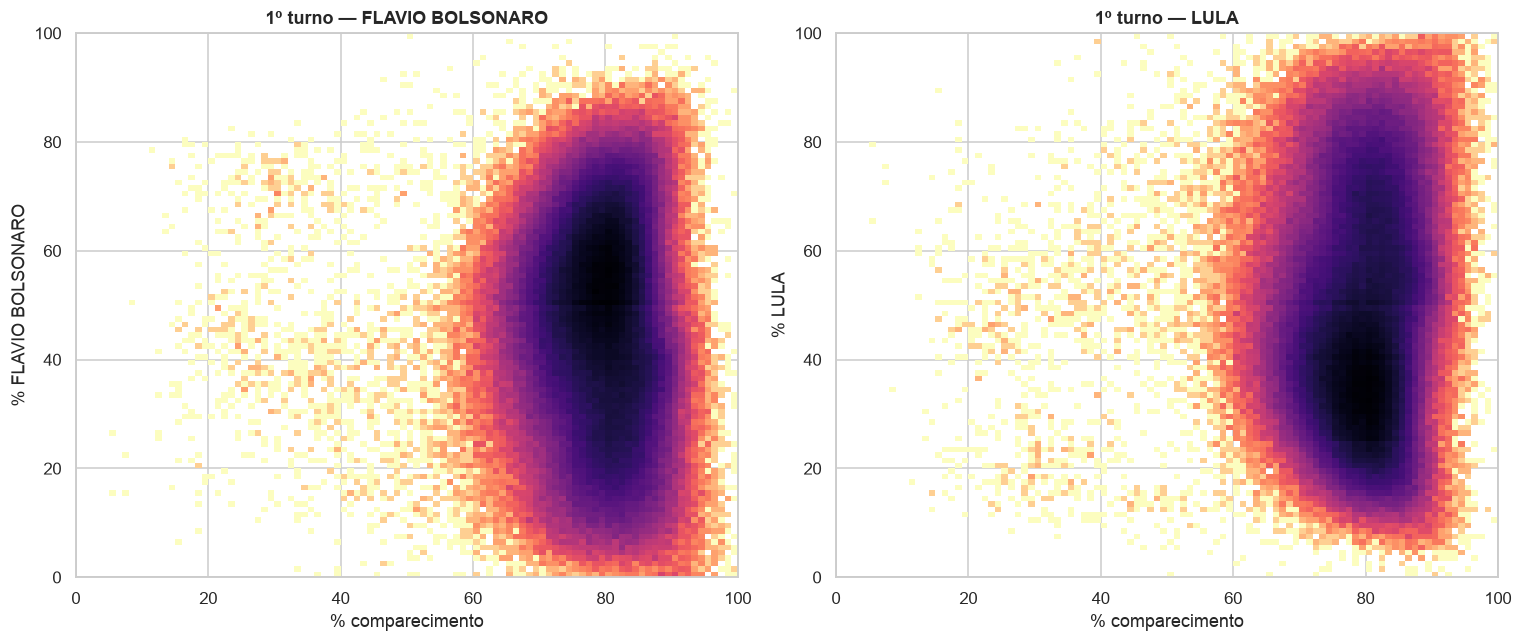

Seções no canto (≥95% comparecimento e ≥95% para um candidato): 27 (0.0054%) — 3,632 votos


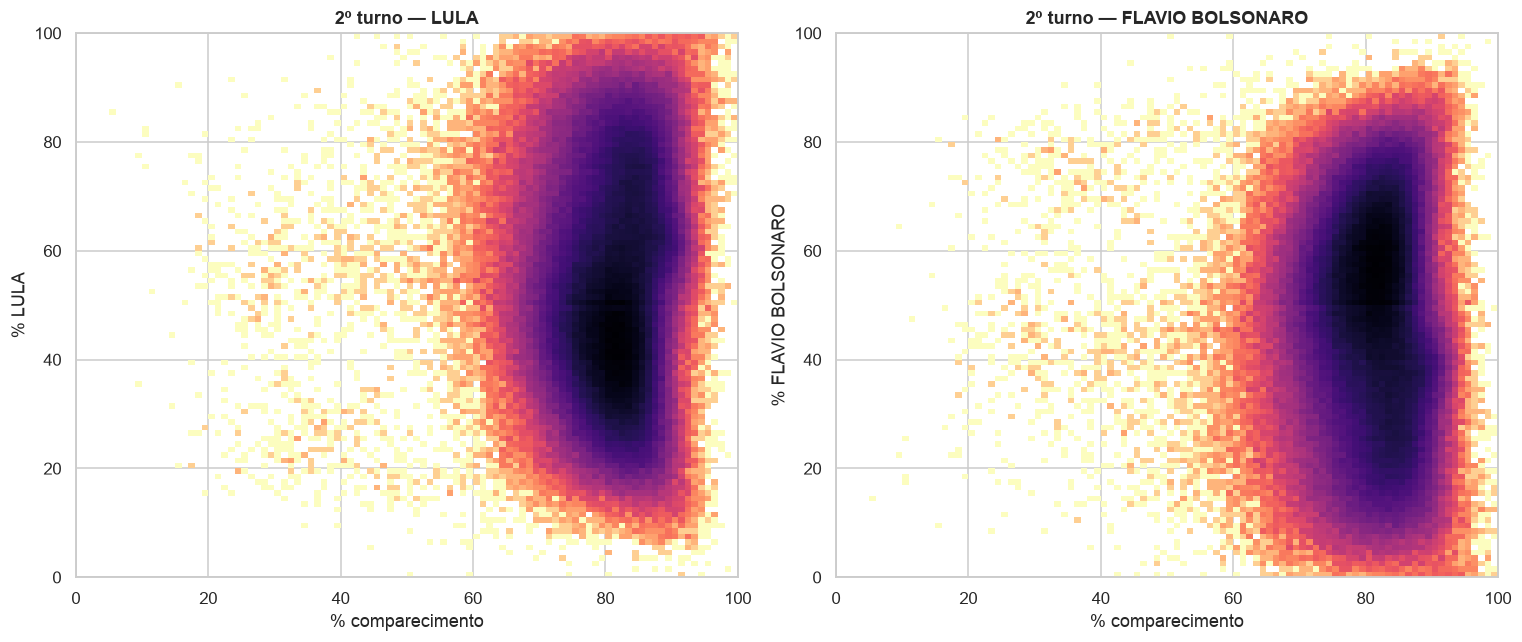

Seções no canto (≥95% comparecimento e ≥95% para um candidato): 65 (0.0130%) — 10,867 votos


In [6]:
for t in TURNOS:
    df = T[t][T[t]["votos_validos"] >= 30]
    cands = A.principais(df, 2)
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for ax, c in zip(axes, cands):
        ax.hist2d(df["comparecimento_pct"].clip(0, 1) * 100, df[c] / df["votos_validos"] * 100,
                  bins=[100, 100], range=[[0, 100], [0, 100]], cmap="magma_r", norm="log")
        ax.set(title=f"{t}º turno — {c}", xlabel="% comparecimento", ylabel=f"% {c}")
    plt.tight_layout(); plt.show()
    canto = (df["comparecimento_pct"] >= 0.95) & (df[cands].max(axis=1) / df["votos_validos"] >= 0.95)
    print(f"Seções no canto (≥95% comparecimento e ≥95% para um candidato): {canto.sum()} "
          f"({canto.mean()*100:.4f}%) — {df.loc[canto, 'votos_validos'].sum():,} votos")

## 5. Testes de dígitos
* **2º dígito de Benford (2BL, Mebane):** para contagens de votos por seção, a média do 2º dígito costuma ficar perto de
  4,187. Desvios aparecem também em eleições limpas (a distribuição depende do tamanho da seção e da competitividade),
  então o teste serve mais para **comparar grupos entre si** do que como prova absoluta.
* **Último dígito:** para contagens ≥ 100 o último dígito deveria ser ~uniforme. Manipulação manual de números costuma
  produzir excesso de 0 e 5.
* O teste do **1º dígito não é usado**: o tamanho limitado das seções o torna inadequado.

Com dezenas de grupos testados, alguns p-valores < 0,05 são esperados por acaso; por isso mostramos também o limiar de
Bonferroni. E com centenas de milhares de seções o qui-quadrado rejeita até desvios minúsculos: o que importa é o
**tamanho** do desvio e se ele é **igual para os dois candidatos** (nesse caso reflete a estrutura das seções).

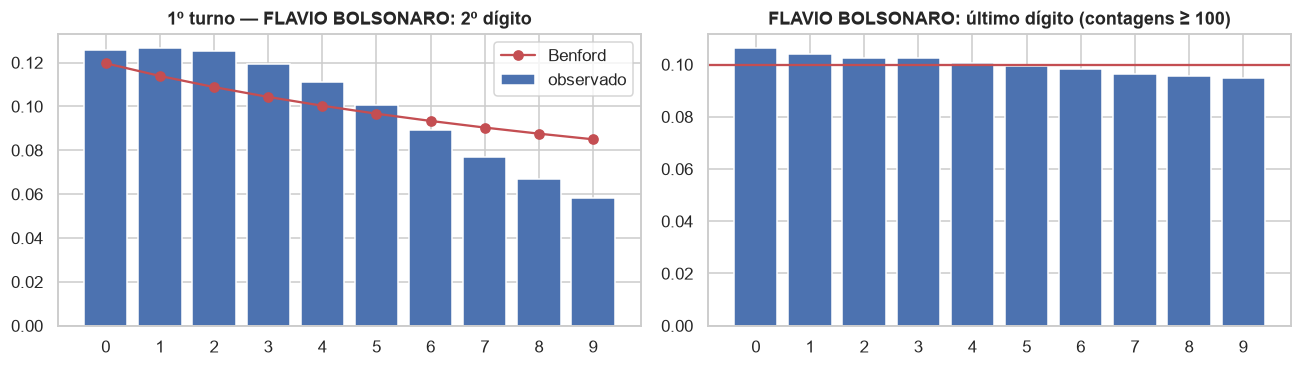

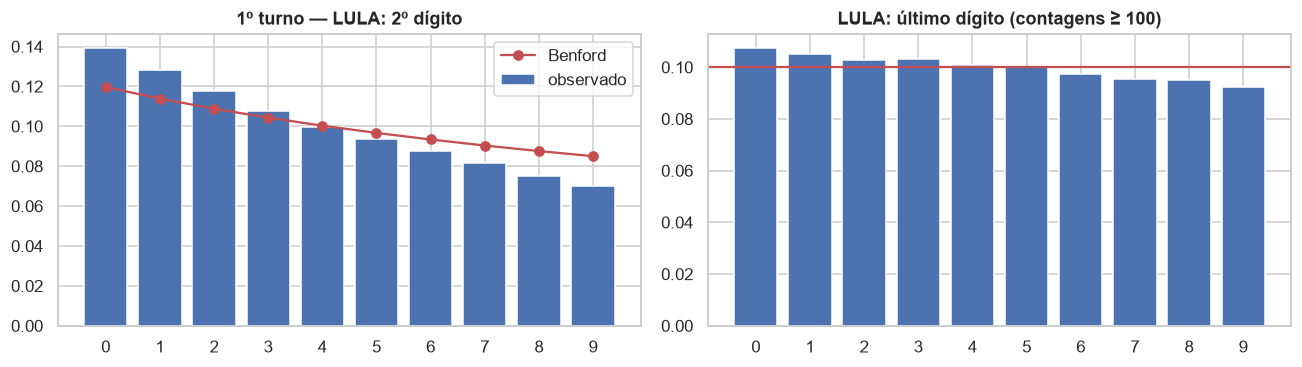

,candidato,n,média 2º díg,esperado,p 2BL,p último díg
0,FLAVIO BOLSONARO,496710,3.816,4.187,0.000,0.000
1,LULA,498891,3.879,4.187,0.000,0.000


1º turno — 56 testes por UF; limiar de Bonferroni = 8.93e-04
   p 2BL < 0,05: 53 (esperado por acaso ≈ 2.8); < Bonferroni: 52
   p último dígito < 0,05: 29; < Bonferroni: 18


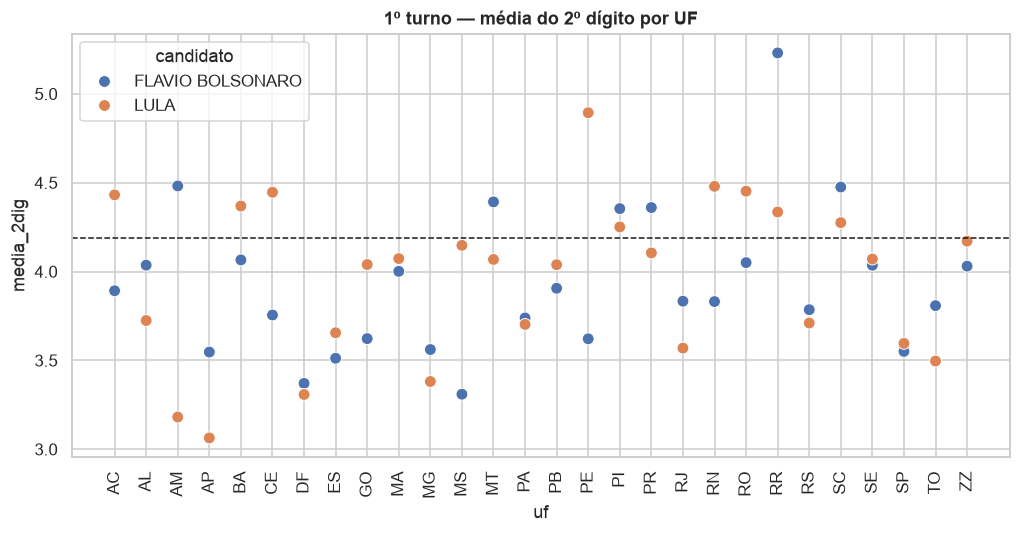

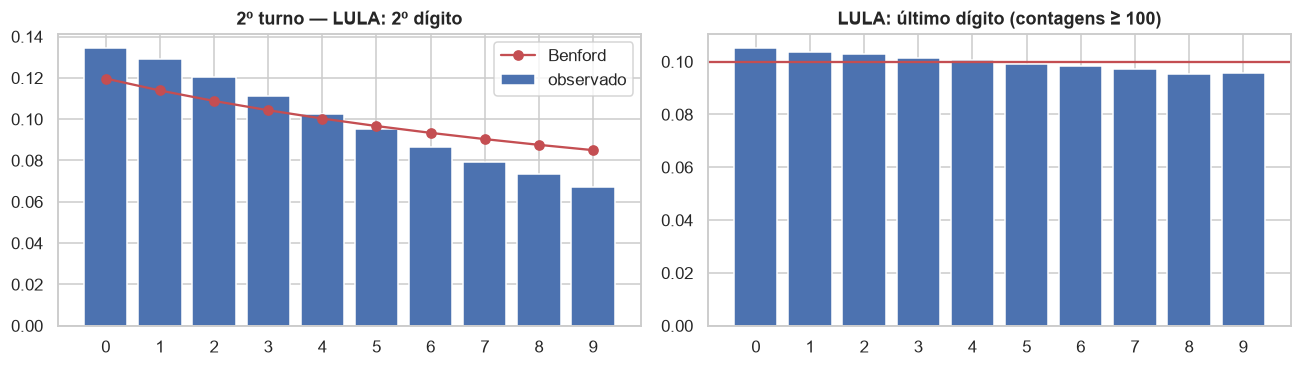

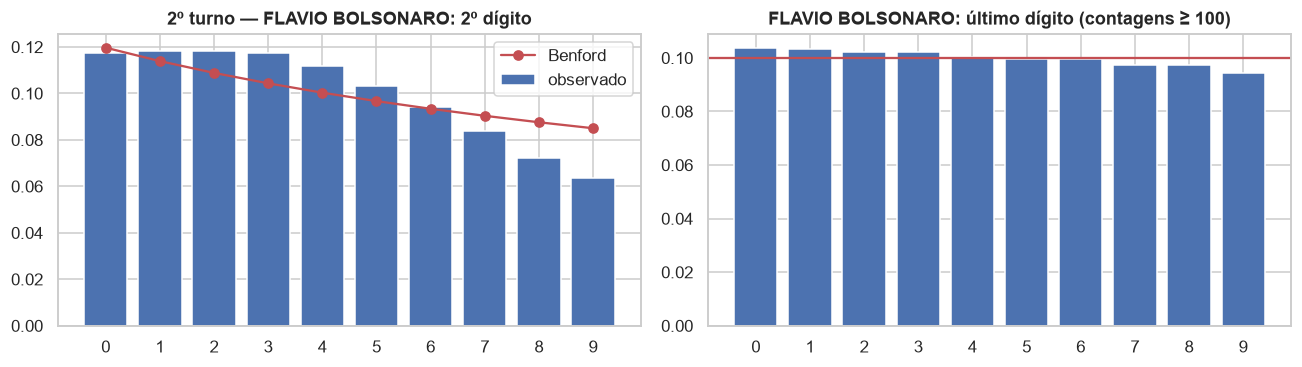

,candidato,n,média 2º díg,esperado,p 2BL,p último díg
0,LULA,499016,3.858,4.187,0.000,0.000
1,FLAVIO BOLSONARO,496587,3.971,4.187,0.000,0.000


2º turno — 56 testes por UF; limiar de Bonferroni = 8.93e-04
   p 2BL < 0,05: 52 (esperado por acaso ≈ 2.8); < Bonferroni: 51
   p último dígito < 0,05: 26; < Bonferroni: 16


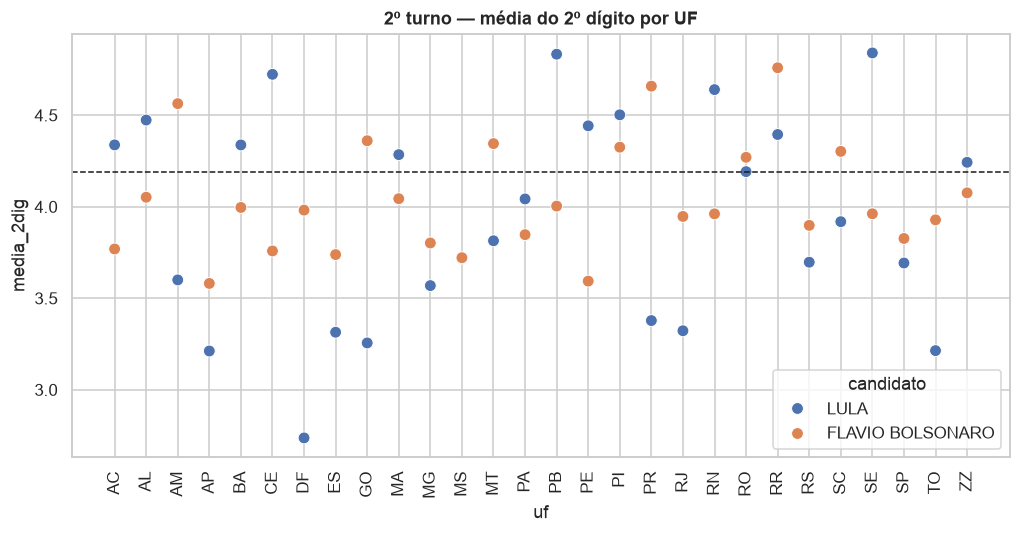

In [7]:
for t in TURNOS:
    df = T[t]
    cands = A.principais(df, 2)
    linhas = []
    for c in cands:
        b = A.segundo_digito(df[c]); u = A.ultimo_digito(df[c])
        linhas.append({"candidato": c, "n": b["n"], "média 2º díg": b["media_2dig"], "esperado": b["media_esperada"],
                       "p 2BL": b["p"], "p último díg": u["p"]})
        fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
        axes[0].bar(range(10), b["obs_freq"], label="observado"); axes[0].plot(range(10), b["esp_freq"], "ro-", label="Benford")
        axes[0].set(title=f"{t}º turno — {c}: 2º dígito", xticks=range(10)); axes[0].legend()
        axes[1].bar(range(10), u["obs_freq"]); axes[1].axhline(0.1, color="r")
        axes[1].set(title=f"{c}: último dígito (contagens ≥ 100)", xticks=range(10))
        plt.tight_layout(); plt.show()
    display(pd.DataFrame(linhas))

    # por UF, simétrico para os dois candidatos
    res = []
    for uf, g in df.groupby("uf", observed=True):
        for c in cands:
            res.append({"uf": uf, "candidato": c, "media_2dig": A.segundo_digito(g[c])["media_2dig"],
                        "p_2BL": A.segundo_digito(g[c])["p"], "p_ultimo": A.ultimo_digito(g[c])["p"]})
    res = pd.DataFrame(res)
    bonf = 0.05 / len(res)
    print(f"{t}º turno — {len(res)} testes por UF; limiar de Bonferroni = {bonf:.2e}")
    print(f"   p 2BL < 0,05: {(res.p_2BL<0.05).sum()} (esperado por acaso ≈ {0.05*len(res):.1f}); < Bonferroni: {(res.p_2BL<bonf).sum()}")
    print(f"   p último dígito < 0,05: {(res.p_ultimo<0.05).sum()}; < Bonferroni: {(res.p_ultimo<bonf).sum()}")
    ax = sns.scatterplot(data=res, x="uf", y="media_2dig", hue="candidato", s=60)
    ax.axhline(4.187, color="k", ls="--", lw=1); ax.set(title=f"{t}º turno — média do 2º dígito por UF"); plt.xticks(rotation=90); plt.show()

## 6. Homogeneidade dentro do mesmo local de votação
Seções do mesmo prédio (escola) atendem eleitores muito parecidos. Para cada seção comparamos a % de um candidato com a
das **outras** seções do mesmo local (z-score quase-binomial, com sobredispersão `φ` estimada nos dados). Em seguida
simulamos quantas seções extremas (|z| > 5) apareceriam só por acaso com essa mesma sobredispersão.

Se o número observado for muito maior que o simulado, há mais heterogeneidade do que o acaso explica — o que pode ter
causas legítimas (seções especiais, presídios, aldeias, seções de transferência temporária) e deve ser inspecionado caso a caso.

1º turno | FLAVIO BOLSONARO     | φ = 1.70 | seções |z|>5: observado 95, esperado ~0.5 (p99 = 2) | BH-FDR 5%: 349


1º turno | LULA                 | φ = 1.69 | seções |z|>5: observado 110, esperado ~0.5 (p99 = 3) | BH-FDR 5%: 353


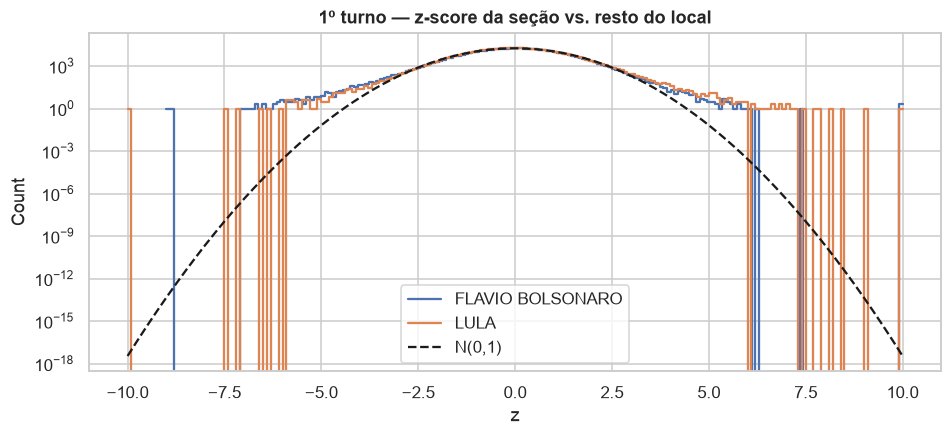

2º turno | LULA                 | φ = 1.73 | seções |z|>5: observado 110, esperado ~0.6 (p99 = 3) | BH-FDR 5%: 381


2º turno | FLAVIO BOLSONARO     | φ = 1.73 | seções |z|>5: observado 110, esperado ~0.7 (p99 = 3) | BH-FDR 5%: 381


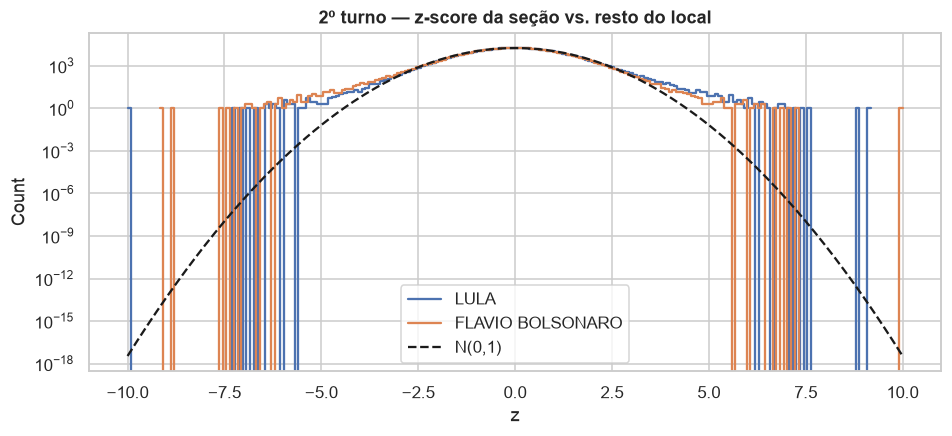

In [8]:
LOCAL = {}
for t in TURNOS:
    df = T[t]
    for c in A.principais(df, 2):
        r = A.desvio_no_local(df, c)
        LOCAL[(t, c)] = r
        sim = A.simular_extremos(r, limiar_z=5)
        print(f"{t}º turno | {c:20s} | φ = {r.phi:.2f} | seções |z|>5: observado {sim['observado']}, "
              f"esperado ~{sim['esperado_medio']:.1f} (p99 = {sim['esperado_p99']:.0f}) | "
              f"BH-FDR 5%: {A.fdr_bh(r.tabela['p_valor']).sum()}")
    fig, ax = plt.subplots(figsize=(10, 4))
    for c in A.principais(df, 2):
        sns.histplot(LOCAL[(t, c)].tabela["z"].clip(-10, 10), bins=200, element="step", fill=False, ax=ax, label=c)
    xs = np.linspace(-10, 10, 400)
    n = len(LOCAL[(t, c)].tabela)
    ax.plot(xs, n * 0.1 * np.exp(-xs**2 / 2) / np.sqrt(2 * np.pi), "k--", label="N(0,1)")
    ax.set(yscale="log", title=f"{t}º turno — z-score da seção vs. resto do local", xlabel="z"); ax.legend(); plt.show()

In [9]:
# Seções mais extremas (para inspeção manual — conferir a seção no site do TSE / BU impresso)
for (t, c), r in LOCAL.items():
    top = r.tabela.reindex(r.tabela["z"].abs().sort_values(ascending=False).index).head(10)
    display(top[["sec_id", "nr_local_votacao", "n_secoes_local", "votos_validos", "prop", "prop_esperada", "z"]]
            .style.set_caption(f"{t}º turno — {c}: 10 seções mais destoantes do próprio local"))

,sec_id,nr_local_votacao,n_secoes_local,votos_validos,prop,prop_esperada,z
122126,MA-9610-71-468,1767,3,234,0.636752,0.236253,11.051639
15611,AM-2372-30-30,1139,3,54,0.018519,0.000100,10.371776
402301,SP-62499-26-402,1236,11,291,0.192440,0.535775,-8.998905
173833,MG-41238-32-336,1040,12,374,0.136364,0.433573,-8.887398
355219,RS-86479-4-4,1015,3,295,0.759322,0.479779,7.364178
498184,ZZ-30341-1-3116,1015,58,437,0.171625,0.384902,-7.021298
60770,CE-14796-44-148,1244,3,214,0.331776,0.631236,-6.957554
326513,RN-18856-14-110,1082,3,311,0.163987,0.413357,-6.843134
419010,SP-62197-23-463,1228,13,214,0.266355,0.566831,-6.797365
410682,SP-70793-121-451,1988,9,258,0.131783,0.397059,-6.673022


,sec_id,nr_local_votacao,n_secoes_local,votos_validos,prop,prop_esperada,z
122126,MA-9610-71-468,1767,3,234,0.324786,0.751527,-11.608212
402301,SP-62499-26-402,1236,11,291,0.718213,0.341321,10.419547
173833,MG-41238-32-336,1040,12,374,0.778075,0.473668,9.059977
419010,SP-62197-23-463,1228,13,214,0.677570,0.326437,8.417723
459506,SP-71072-251-330,1074,21,342,0.640351,0.364811,8.134227
86743,ES-57053-52-443,1732,8,371,0.606469,0.352941,7.852248
498184,ZZ-30341-1-3116,1015,58,437,0.762014,0.522472,7.703623
64106,CE-13854-27-339,1864,3,259,0.644788,0.855967,-7.437835
410682,SP-70793-121-451,1988,9,258,0.794574,0.494690,7.403247
260321,PR-74160-73-170,1155,4,206,0.480583,0.211454,7.269038


,sec_id,nr_local_votacao,n_secoes_local,votos_validos,prop,prop_esperada,z
111564,MA-9610-71-468,1767,3,238,0.365546,0.792683,-12.370193
439967,SP-62499-26-402,1236,11,290,0.758621,0.410410,9.173707
129505,MG-41238-32-336,1040,12,368,0.845109,0.543566,8.837835
491495,SP-62197-23-463,1228,13,221,0.723982,0.396411,7.576122
285365,PR-74160-73-170,1155,4,214,0.542056,0.252212,7.429965
237003,PE-25852-79-157,1112,5,193,0.797927,0.949474,-7.314959
498576,ZZ-30341-1-3116,1015,58,501,0.806387,0.600203,7.169591
365015,RS-87556-117-66,1260,4,259,0.158301,0.444295,-7.049162
328233,RN-18856-14-110,1082,3,294,0.877551,0.615955,7.018220
408279,SP-71072-251-330,1074,21,353,0.713881,0.471313,6.947913


,sec_id,nr_local_votacao,n_secoes_local,votos_validos,prop,prop_esperada,z
111564,MA-9610-71-468,1767,3,238,0.634454,0.207317,12.370193
439967,SP-62499-26-402,1236,11,290,0.241379,0.589590,-9.173707
129505,MG-41238-32-336,1040,12,368,0.154891,0.456434,-8.837835
491495,SP-62197-23-463,1228,13,221,0.276018,0.603589,-7.576122
285365,PR-74160-73-170,1155,4,214,0.457944,0.747788,-7.429965
237003,PE-25852-79-157,1112,5,193,0.202073,0.050526,7.314959
498576,ZZ-30341-1-3116,1015,58,501,0.193613,0.399797,-7.169591
365015,RS-87556-117-66,1260,4,259,0.841699,0.555705,7.049162
328233,RN-18856-14-110,1082,3,294,0.122449,0.384045,-7.018220
408279,SP-71072-251-330,1074,21,353,0.286119,0.528687,-6.947913


## 7. Anomalias multivariadas (Isolation Forest)
Combinação de variáveis por seção: comparecimento, % de brancos+nulos, % do 1º colocado, % de eleitores liberados
sem biometria, tempo entre encerramento e emissão do BU, e desvio em relação ao local de votação. O algoritmo aponta
seções "isoladas" — é uma ferramenta de **triagem** para inspeção, não um teste de hipótese. Exterior excluído.

In [10]:
# O exterior (ZZ) é estruturalmente diferente (comparecimento muito baixo, seções enormes) e
# dominaria a triagem; por isso fica de fora aqui.
for t in TURNOS:
    df = T[t][T[t]["uf"] != "ZZ"]
    c = A.principais(df, 1)[0]
    z = LOCAL[(t, c)].tabela.set_index("sec_id")["z"]
    X = pd.DataFrame({
        "comparecimento": df["comparecimento_pct"],
        "branco_nulo": (df["BRANCO"] + df["NULO"]) / df["votos_total"].replace(0, np.nan),
        "pct_1o": df[c] / df["votos_validos"].replace(0, np.nan),
        "sem_biometria": df["qt_biom_sem_hab"] / df["qt_comparecimento"].replace(0, np.nan),
        "min_ate_bu": (df["dt_emissao_bu"] - df["dt_encerramento"]).dt.total_seconds() / 60,
        "z_local": df["sec_id"].map(z),
    }, index=df.index).fillna(0).clip(-50, 500)
    iso = IsolationForest(n_estimators=200, contamination=0.001, random_state=0).fit(X)
    df_t = df.assign(score=-iso.score_samples(X), anomalia=iso.predict(X) == -1)
    print(f"{t}º turno: {df_t['anomalia'].sum()} seções sinalizadas (0,1% por construção)")
    display(df_t[df_t.anomalia].groupby("regiao", observed=True).size().rename("seções sinalizadas").to_frame()
            .join(df_t.groupby("regiao", observed=True).size().rename("total")).assign(pct=lambda d: d.iloc[:,0]/d.total*100))
    display(df_t.nlargest(15, "score")[["sec_id", "nm_municipio", "qt_aptos", "comparecimento_pct", "votos_validos", c,
                                         "BRANCO", "NULO", "qt_biom_sem_hab", "score"]])

1º turno: 498 seções sinalizadas (0,1% por construção)


,seções sinalizadas,total,pct
regiao,,,
Centro-Oeste,26,38048,0.068
Nordeste,213,140828,0.151
Norte,34,43769,0.078
Sudeste,167,203237,0.082
Sul,58,72015,0.081


,sec_id,nm_municipio,qt_aptos,comparecimento_pct,votos_validos,FLAVIO BOLSONARO,BRANCO,NULO,qt_biom_sem_hab,score
172742,MG-48577-180-158,MONTE AZUL,172,0.756,109,9,3,18,31,0.714
9280,AL-28835-20-44,TRAIPU,238,0.685,139,14,2,22,34,0.708
349061,RS-85758-148-357,CAMPINAS DO SUL,72,0.958,69,66,0,0,17,0.700
154590,MG-52531-237-384,SÃO JOÃO DO PARAÍSO,45,0.956,37,1,1,5,9,0.698
297938,RJ-60011-219-263,RIO DE JANEIRO,429,0.692,262,131,13,22,49,0.696
34631,BA-34134-171-409,CAMAÇARI,24,0.417,10,0,0,0,4,0.690
103815,GO-93050-99-49,CAVALCANTE,218,0.697,129,6,0,23,41,0.688
39162,BA-37877-105-83,PIATÃ,166,0.524,69,10,2,16,16,0.688
8148,AL-28835-20-45,TRAIPU,287,0.672,156,9,4,33,24,0.687
245671,PE-25615-44-130,SÃO CAITANO,297,0.727,194,22,6,16,136,0.686


2º turno: 498 seções sinalizadas (0,1% por construção)


,seções sinalizadas,total,pct
regiao,,,
Centro-Oeste,18,38048,0.047
Nordeste,146,140828,0.104
Norte,102,43769,0.233
Sudeste,163,203237,0.080
Sul,69,72015,0.096


,sec_id,nm_municipio,qt_aptos,comparecimento_pct,votos_validos,LULA,BRANCO,NULO,qt_biom_sem_hab,score
363560,RS-85251-92-14,ARROIO GRANDE,59,0.678,35,11,3,2,13,0.710
344716,RS-85758-148-357,CAMPINAS DO SUL,72,0.986,71,1,0,0,21,0.708
135189,MG-41742-148-167,BONITO DE MINAS,24,0.458,10,9,0,1,2,0.698
283988,PR-77917-30-179,PRUDENTÓPOLIS,59,0.475,22,5,0,6,6,0.692
153491,MG-53414-262-42,SERRO,289,0.606,160,112,6,9,47,0.688
242555,PE-25615-44-130,SÃO CAITANO,297,0.808,223,205,5,12,65,0.683
420250,SP-71072-381-729,SÃO PAULO,74,0.797,51,42,6,2,2,0.682
419,AC-1082-4-317,RODRIGUES ALVES,140,0.557,71,8,3,4,1,0.681
357236,RS-85170-20-14,ARATIBA,197,0.954,186,41,1,1,48,0.681
113418,MA-7714-14-149,CURURUPU,49,0.612,30,29,0,0,8,0.680


## 8. Aspectos operacionais
Horários (convertidos para Brasília), tempo até a emissão do BU, liberação de eleitores sem biometria e data de carga das
urnas. Servem para verificar se a operação foi homogênea no país.

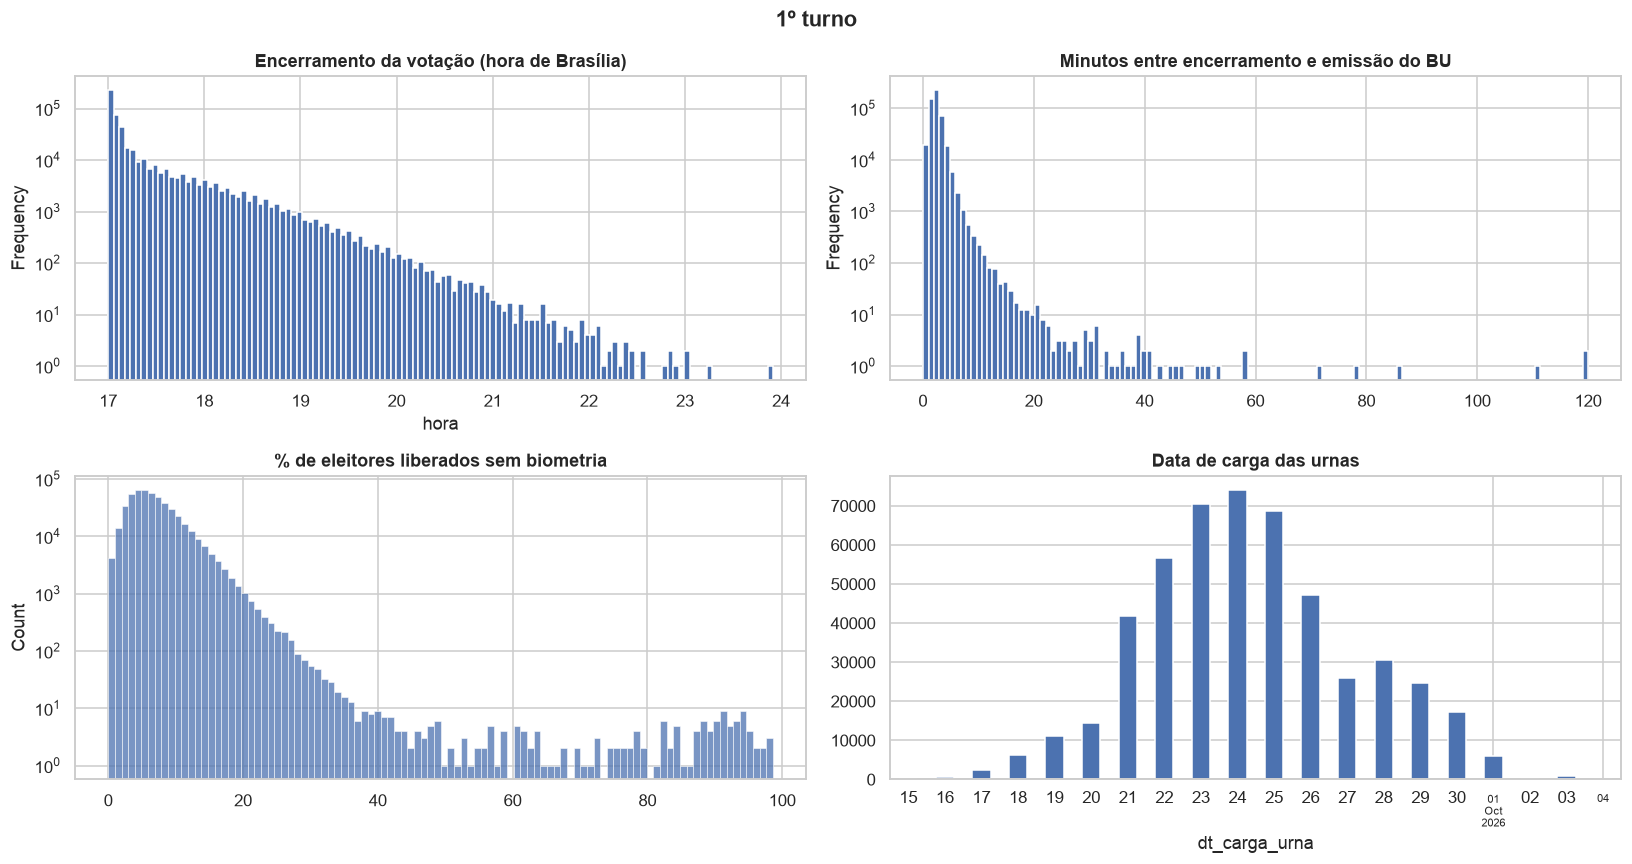

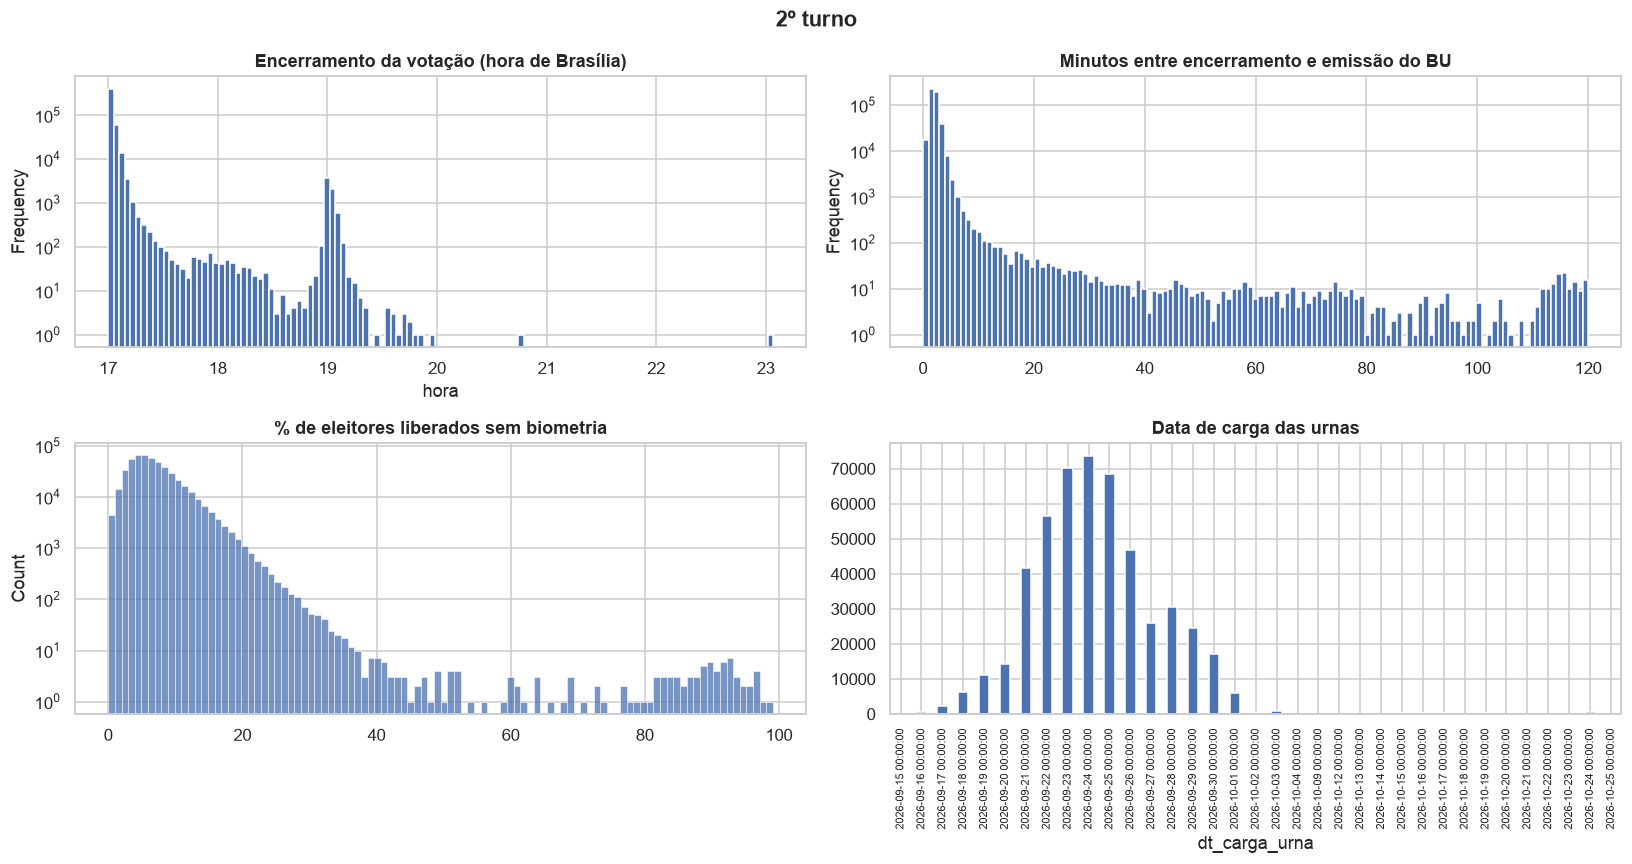

In [11]:
for t in TURNOS:
    df = T[t]
    fig, axes = plt.subplots(2, 2, figsize=(15, 8))
    (df["dt_encerramento_bsb"].dt.hour + df["dt_encerramento_bsb"].dt.minute / 60).plot.hist(bins=120, ax=axes[0, 0], log=True)
    axes[0, 0].set(title="Encerramento da votação (hora de Brasília)", xlabel="hora")
    mins = ((df["dt_emissao_bu"] - df["dt_encerramento"]).dt.total_seconds() / 60).clip(-5, 120)
    mins.plot.hist(bins=125, ax=axes[0, 1], log=True); axes[0, 1].set(title="Minutos entre encerramento e emissão do BU")
    sb = (df["qt_biom_sem_hab"] / df["qt_comparecimento"].replace(0, np.nan) * 100).clip(0, 100)
    sns.histplot(sb, bins=100, ax=axes[1, 0]); axes[1, 0].set(title="% de eleitores liberados sem biometria", yscale="log")
    df["dt_carga_urna"].dt.floor("D").value_counts().sort_index().plot.bar(ax=axes[1, 1])
    axes[1, 1].set(title="Data de carga das urnas"); axes[1, 1].tick_params(axis="x", labelsize=7)
    plt.suptitle(f"{t}º turno", fontweight="bold"); plt.tight_layout(); plt.show()

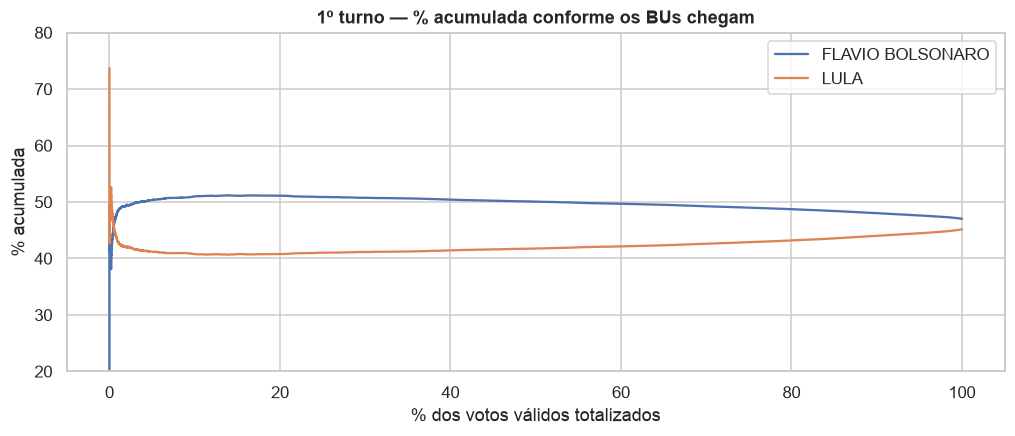

Mediana do horário de recebimento por região:


,dt_bu_recebido
regiao,
Exterior,2026-10-04 17:08:51
Centro-Oeste,2026-10-04 18:20:04
Sul,2026-10-04 18:24:45
Norte,2026-10-04 18:29:49
Sudeste,2026-10-04 18:55:10
Nordeste,2026-10-04 19:01:07


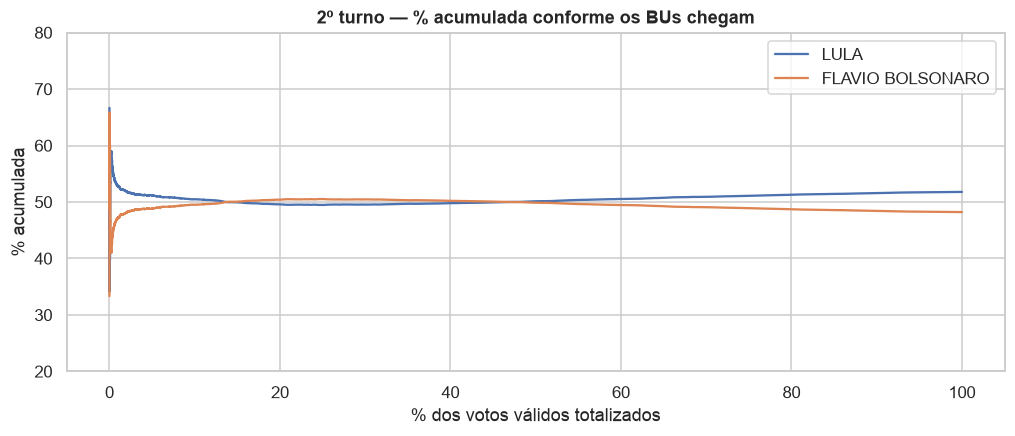

Mediana do horário de recebimento por região:


,dt_bu_recebido
regiao,
Exterior,2026-10-25 17:05:15
Norte,2026-10-25 19:57:20
Centro-Oeste,2026-10-25 20:05:17
Sul,2026-10-25 20:08:17
Nordeste,2026-10-25 20:27:14
Sudeste,2026-10-25 20:41:23


In [12]:
# Ordem de chegada dos BUs: a % acumulada muda ao longo da apuração porque regiões diferentes
# (e o exterior) totalizam em horários diferentes — não porque votos "mudam".
for t in TURNOS:
    df = T[t].dropna(subset=["dt_bu_recebido"]).sort_values("dt_bu_recebido")
    a, b = A.principais(df, 2)
    acum = df[[a, b, "votos_validos"]].cumsum()
    frac = acum["votos_validos"] / acum["votos_validos"].iloc[-1] * 100
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(frac, acum[a] / acum["votos_validos"] * 100, label=a)
    ax.plot(frac, acum[b] / acum["votos_validos"] * 100, label=b)
    ax.set(title=f"{t}º turno — % acumulada conforme os BUs chegam", xlabel="% dos votos válidos totalizados", ylabel="% acumulada", ylim=(20, 80))
    ax.legend(); plt.show()
    ordem = df.groupby("regiao", observed=True)["dt_bu_recebido"].median().sort_values()
    print("Mediana do horário de recebimento por região:"); display(ordem.to_frame())

## 9. Do 1º para o 2º turno
Ligando cada seção nos dois turnos, prevemos a % de cada finalista no 2º turno a partir da composição do voto no 1º
(modelo ecológico com efeito fixo de município). Seções com resíduo grande são as que se comportaram de forma muito
diferente das demais seções do município com o mesmo perfil de 1º turno.

Seções presentes nos dois turnos: 499,205 (1º: 499,206, 2º: 499,205)


Alvo: % de LULA no 2º turno | R² (dentro do município) = 0.092 | φ = 5.42


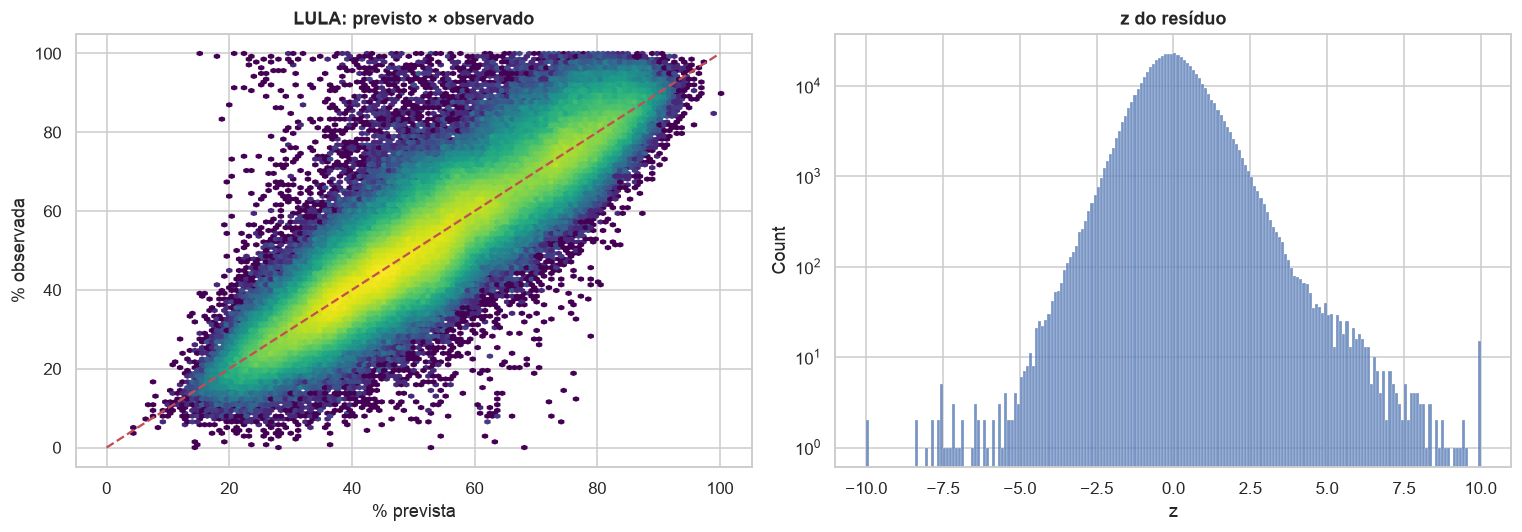

,uf,cd_municipio,nr_zona,nr_secao,sec_id,regiao,votos_validos_2t,prop_2t,prop_prevista,residuo,z
258479,PI,12467,19,87,PI-12467-19-87,Nordeste,158,0.899,1.002,-0.103,-17.629
195847,MT,90280,28,200,MT-90280-28-200,Centro-Oeste,309,1.000,0.224,0.776,14.068
191678,MT,98710,32,279,MT-98710-32-279,Centro-Oeste,203,0.995,0.178,0.817,13.080
193571,MT,90069,53,163,MT-90069-53-163,Centro-Oeste,286,0.983,0.245,0.738,12.466
196726,MT,99058,44,284,MT-99058-44-284,Centro-Oeste,145,1.000,0.150,0.850,12.332
196015,MT,98310,35,321,MT-98310-35-321,Centro-Oeste,352,0.957,0.276,0.682,12.292
193576,MT,90069,53,165,MT-90069-53-165,Centro-Oeste,233,0.983,0.235,0.748,11.557
338986,RR,3107,7,56,RR-3107-7-56,Norte,319,0.078,0.727,-0.649,-11.176
333851,RO,51,30,125,RO-51-30-125,Norte,236,0.992,0.264,0.727,10.879
213341,PA,5452,53,218,PA-5452-53-218,Norte,273,1.000,0.300,0.700,10.843


|z| > 5 → 446 seções; com z positivo (favor de LULA): 392, negativo: 54
   Obs.: assimetria aqui NÃO é, por si, sinal de viés — a migração dos votos de 3º colocados não é linear (num teste com 2º turno sintético e sem manipulação alguma, o modelo também deu resíduos assimétricos).


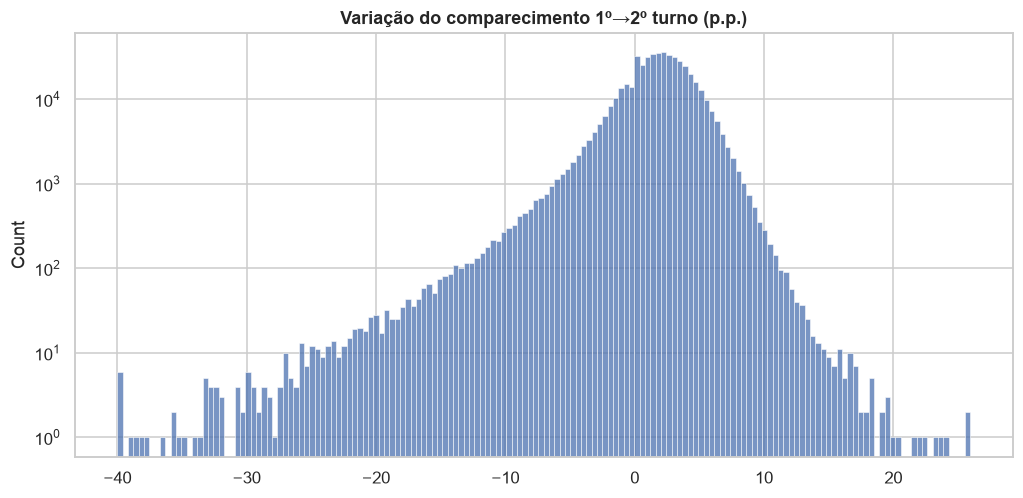

In [13]:
if T[2] is None:
    print("2º turno ainda não disponível — seção pulada.")
else:
    t1, t2 = T[1], T[2]
    M = A.juntar_turnos(t1, t2)
    print(f"Seções presentes nos dois turnos: {len(M):,} (1º: {len(t1):,}, 2º: {len(t2):,})")
    alvo = A.principais(t2, 1)[0]
    TR = A.modelo_transicao(M, A.candidatos(t1)[:8], alvo)
    print(f"Alvo: % de {alvo} no 2º turno | R² (dentro do município) = {TR.attrs['r2']:.3f} | φ = {TR.attrs['phi']:.2f}")
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].hexbin(TR["prop_prevista"] * 100, TR["prop_2t"] * 100, gridsize=120, bins="log", cmap="viridis")
    axes[0].plot([0, 100], [0, 100], "r--"); axes[0].set(xlabel="% prevista", ylabel="% observada", title=f"{alvo}: previsto × observado")
    sns.histplot(TR["z"].clip(-10, 10), bins=200, ax=axes[1]); axes[1].set(yscale="log", title="z do resíduo")
    plt.tight_layout(); plt.show()
    display(TR.reindex(TR["z"].abs().sort_values(ascending=False).index).head(15))
    print(f"|z| > 5 → {int((TR['z'].abs()>5).sum())} seções; com z positivo (favor de {alvo}): {int((TR['z']>5).sum())}, "
          f"negativo: {int((TR['z']<-5).sum())}")
    print("   Obs.: assimetria aqui NÃO é, por si, sinal de viés — a migração dos votos de 3º colocados não é linear "
          "(num teste com 2º turno sintético e sem manipulação alguma, o modelo também deu resíduos assimétricos).")
    # comparecimento entre turnos
    dc = (M["qt_comparecimento_2t"] / M["qt_aptos_2t"] - M["qt_comparecimento_1t"] / M["qt_aptos_1t"]) * 100
    ax = sns.histplot(dc.clip(-40, 40), bins=160); ax.set(title="Variação do comparecimento 1º→2º turno (p.p.)", yscale="log"); plt.show()

## 10. Resumo automático

In [14]:
for t in TURNOS:
    df = T[t]
    v, s, m = A.margem(df)
    cons = A.checar_consistencia(df)
    print(f"— {t}º turno: {v} à frente de {s} por {m:,} votos ({m/df['votos_validos'].sum()*100:.2f} p.p. dos válidos).")
    print(f"  Violações aritméticas: {int(cons['secoes_violando'].sum())} ocorrências em {len(df):,} seções.")
    for c in A.principais(df, 2):
        sim = A.simular_extremos(LOCAL[(t, c)], 5)
        print(f"  {c}: {sim['observado']} seções muito destoantes do próprio local (acaso: ~{sim['esperado_medio']:.0f}).")
print("\nInterpretação: anomalias estatísticas identificam seções para inspeção; só a verificação do BU impresso, "
      "dos logs da urna e das atas da seção pode dizer se houve erro ou irregularidade.")

— 1º turno: FLAVIO BOLSONARO à frente de LULA por 2,224,965 votos (1.86 p.p. dos válidos).
  Violações aritméticas: 0 ocorrências em 499,206 seções.


  FLAVIO BOLSONARO: 95 seções muito destoantes do próprio local (acaso: ~1).


  LULA: 110 seções muito destoantes do próprio local (acaso: ~1).
— 2º turno: LULA à frente de FLAVIO BOLSONARO por 4,430,191 votos (3.57 p.p. dos válidos).
  Violações aritméticas: 0 ocorrências em 499,205 seções.


  LULA: 110 seções muito destoantes do próprio local (acaso: ~1).


  FLAVIO BOLSONARO: 110 seções muito destoantes do próprio local (acaso: ~1).

Interpretação: anomalias estatísticas identificam seções para inspeção; só a verificação do BU impresso, dos logs da urna e das atas da seção pode dizer se houve erro ou irregularidade.
